In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

url = "https://raw.githubusercontent.com/IBM/watson-studio-learning-path-assets/master/data/customer-churn-kaggle.csv"
df = pd.read_csv(url)
df.head()

,state,account length,area code,phone number,international plan,voice mail plan,number vmail messages,total day minutes,total day calls,total day charge,...,total eve calls,total eve charge,total night minutes,total night calls,total night charge,total intl minutes,total intl calls,total intl charge,customer service calls,churn
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,358-1921,no,no,0,243.4,114,41.38,...,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,375-9999,yes,no,0,299.4,71,50.90,...,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,330-6626,yes,no,0,166.7,113,28.34,...,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   state                   3333 non-null   str    
 1   account length          3333 non-null   int64  
 2   area code               3333 non-null   int64  
 3   phone number            3333 non-null   str    
 4   international plan      3333 non-null   str    
 5   voice mail plan         3333 non-null   str    
 6   number vmail messages   3333 non-null   int64  
 7   total day minutes       3333 non-null   float64
 8   total day calls         3333 non-null   int64  
 9   total day charge        3333 non-null   float64
 10  total eve minutes       3333 non-null   float64
 11  total eve calls         3333 non-null   int64  
 12  total eve charge        3333 non-null   float64
 13  total night minutes     3333 non-null   float64
 14  total night calls       3333 non-null   int64  
 15

In [3]:
df.describe()

,account length,area code,number vmail messages,total day minutes,total day calls,total day charge,total eve minutes,total eve calls,total eve charge,total night minutes,total night calls,total night charge,total intl minutes,total intl calls,total intl charge,customer service calls
count,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000
mean,101.064806,437.182418,8.099010,179.775098,100.435644,30.562307,200.980348,100.114311,17.083540,200.872037,100.107711,9.039325,10.237294,4.479448,2.764581,1.562856
std,39.822106,42.371290,13.688365,54.467389,20.069084,9.259435,50.713844,19.922625,4.310668,50.573847,19.568609,2.275873,2.791840,2.461214,0.753773,1.315491
min,1.000000,408.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,23.200000,33.000000,1.040000,0.000000,0.000000,0.000000,0.000000
25%,74.000000,408.000000,0.000000,143.700000,87.000000,24.430000,166.600000,87.000000,14.160000,167.000000,87.000000,7.520000,8.500000,3.000000,2.300000,1.000000
50%,101.000000,415.000000,0.000000,179.400000,101.000000,30.500000,201.400000,100.000000,17.120000,201.200000,100.000000,9.050000,10.300000,4.000000,2.780000,1.000000
75%,127.000000,510.000000,20.000000,216.400000,114.000000,36.790000,235.300000,114.000000,20.000000,235.300000,113.000000,10.590000,12.100000,6.000000,3.270000,2.000000
max,243.000000,510.000000,51.000000,350.800000,165.000000,59.640000,363.700000,170.000000,30.910000,395.000000,175.000000,17.770000,20.000000,20.000000,5.400000,9.000000


In [4]:
# count = el numero de ocurrencias de cada valor en una columna
# mean = el promedio de los valores en una columna
# std = la desviación estándar de los valores en una columna
# min = el valor mínimo en una columna
# max = el valor máximo en una columna
# 25% = el percentil 25 de los valores en una columna
# 50% = el percentil 50 de los valores en una columna (mediana)
# 75% = el percentil 75 de los valores en una columna
# max = el valor máximo en una columna

In [5]:
# Necesitamos saber si tiene valores nulos.
df.isnull().sum()

state                     0
account length            0
area code                 0
phone number              0
international plan        0
voice mail plan           0
number vmail messages     0
total day minutes         0
total day calls           0
total day charge          0
total eve minutes         0
total eve calls           0
total eve charge          0
total night minutes       0
total night calls         0
total night charge        0
total intl minutes        0
total intl calls          0
total intl charge         0
customer service calls    0
churn                     0
dtype: int64

In [6]:
# Vamos a dividir tanto los Variables numéricos como variables Categóricos.
numerical_features = df.select_dtypes(include=['int64', 'float64']).columns
categorical_features = df.select_dtypes(include=['object']).columns

print("Variables numéricas:", numerical_features)
print("Variables categóricas:", categorical_features)

Variables numéricas: Index(['account length', 'area code', 'number vmail messages',
       'total day minutes', 'total day calls', 'total day charge',
       'total eve minutes', 'total eve calls', 'total eve charge',
       'total night minutes', 'total night calls', 'total night charge',
       'total intl minutes', 'total intl calls', 'total intl charge',
       'customer service calls'],
      dtype='str')
Variables categóricas: Index(['state', 'phone number', 'international plan', 'voice mail plan'],
      dtype='str')


/tmp/ipykernel_3579/2993228253.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(include=['object']).columns


In [7]:
df['churn'].value_counts(normalize=True) * 100

churn
False    85.508551
True     14.491449
Name: proportion, dtype: float64

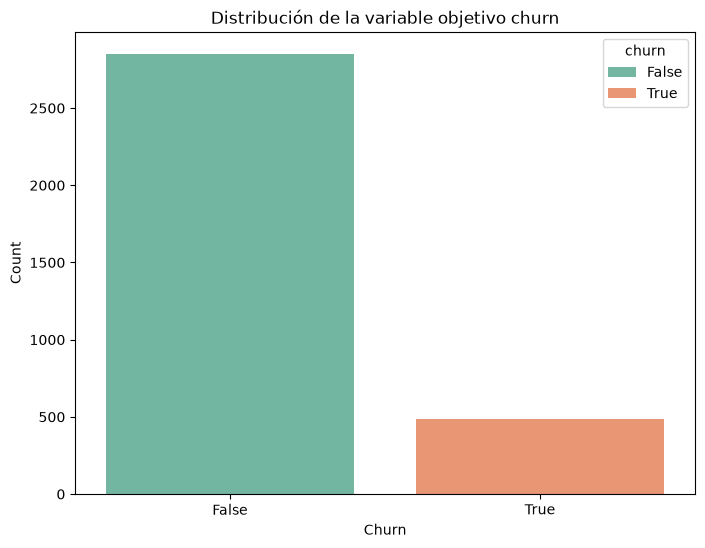

In [8]:
# Vamos a hacer un gráfico Para poder. Analizar la variable objetivo churn le damos un color distinto para diferenciarlos
plt.figure(figsize=(8, 6))
sns.countplot(x='churn', data=df, palette='Set2', hue='churn')
plt.xlabel('Churn')
plt.ylabel('Count')
plt.title('Distribución de la variable objetivo churn')
plt.show()

In [9]:
# Ahora quiero los valores Categóricos. ¿Cuántos valores únicos tiene cada columna categórica?
for col in categorical_features:
    print(f"{col}: {df[col].nunique()} valores únicos")

state: 51 valores únicos
phone number: 3333 valores únicos
international plan: 2 valores únicos
voice mail plan: 2 valores únicos


In [10]:
df.groupby('churn').mean(numeric_only=True).T.round(2)

churn,False,True
account length,100.79,102.66
area code,437.07,437.82
number vmail messages,8.60,5.12
total day minutes,175.18,206.91
total day calls,100.28,101.34
total day charge,29.78,35.18
total eve minutes,199.04,212.41
total eve calls,100.04,100.56
total eve charge,16.92,18.05
total night minutes,200.13,205.23


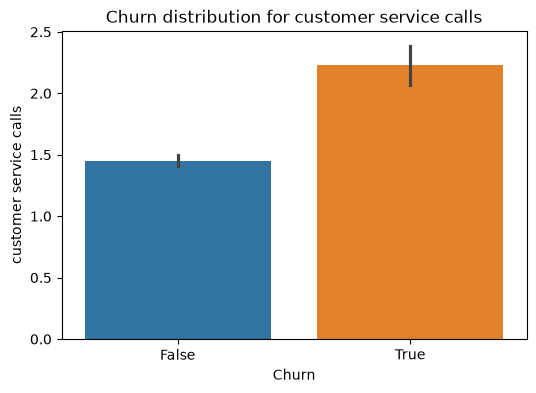

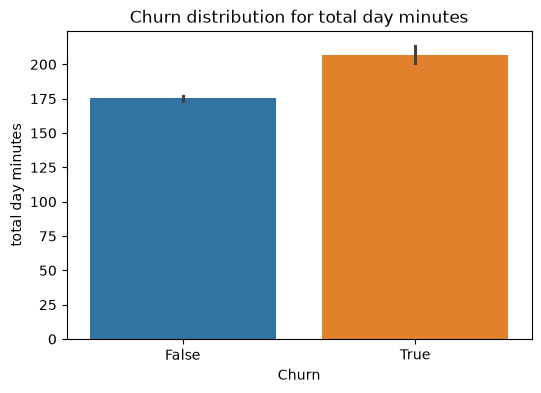

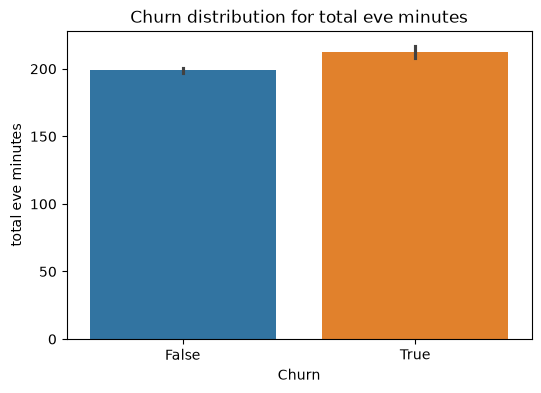

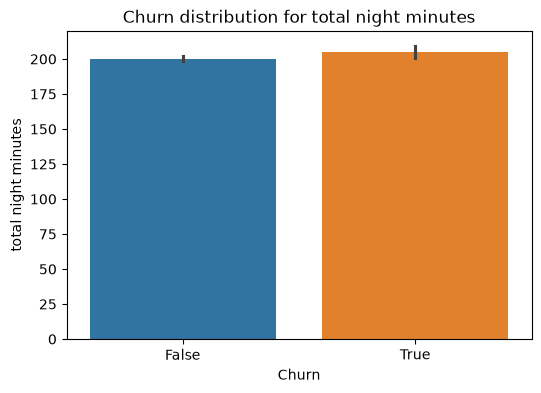

In [11]:
variables_sospechosas = ['customer service calls',
                         'total day minutes',
                         'total eve minutes',
                         'total night minutes']
for var in variables_sospechosas:
    plt.figure(figsize=(6,4))
    sns.barplot(data=df, x='churn',y=var, hue='churn', legend=False)
    plt.xlabel('Churn')
    plt.ylabel(var)
    plt.title(f'Churn distribution for {var}')
    plt.show()
    

In [12]:
categorical_features = ['state', 'international plan', 'voice mail plan']
for categoria in categorical_features:
    print(f'Churn distribution for {categoria}')
    resultado = pd.crosstab(df[categoria], df['churn'], normalize='index') * 100
    print(resultado.round(2))
    print()

Churn distribution for state
churn  False  True 
state              
AK     94.23   5.77
AL     90.00  10.00
AR     80.00  20.00
AZ     93.75   6.25
CA     73.53  26.47
CO     86.36  13.64
CT     83.78  16.22
DC     90.74   9.26
DE     85.25  14.75
FL     87.30  12.70
GA     85.19  14.81
HI     94.34   5.66
IA     93.18   6.82
ID     87.67  12.33
IL     91.38   8.62
IN     87.32  12.68
KS     81.43  18.57
KY     86.44  13.56
LA     92.16   7.84
MA     83.08  16.92
MD     75.71  24.29
ME     79.03  20.97
MI     78.08  21.92
MN     82.14  17.86
MO     88.89  11.11
MS     78.46  21.54
MT     79.41  20.59
NC     83.82  16.18
ND     90.32   9.68
NE     91.80   8.20
NH     83.93  16.07
NJ     73.53  26.47
NM     90.32   9.68
NV     78.79  21.21
NY     81.93  18.07
OH     87.18  12.82
OK     85.25  14.75
OR     85.90  14.10
PA     82.22  17.78
RI     90.77   9.23
SC     76.67  23.33
SD     86.67  13.33
TN     90.57   9.43
TX     75.00  25.00
UT     86.11  13.89
VA     93.51   6.49
VT     89.0

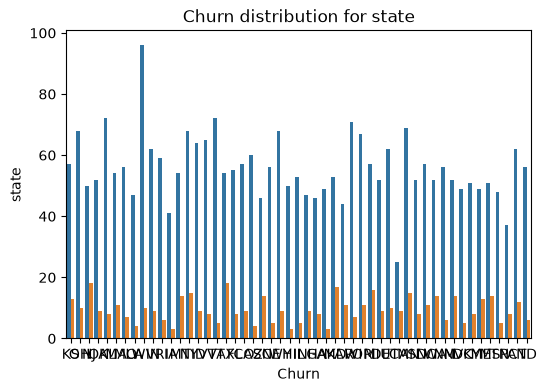

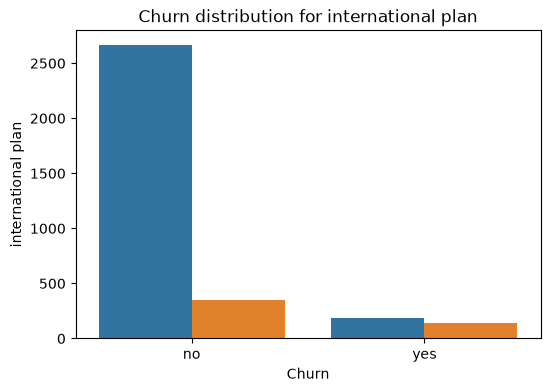

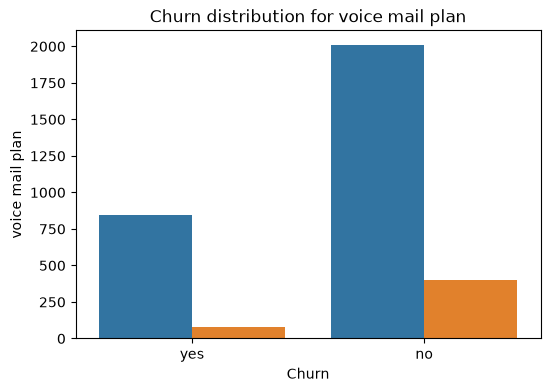

In [13]:
for categorical in categorical_features:
    plt.figure(figsize=(6,4))
    sns.countplot(data=df, x=categorical, hue='churn', legend=False)
    plt.xlabel('Churn')
    plt.ylabel(categorical)
    plt.title(f'Churn distribution for {categorical}')
    plt.show()

In [14]:
# tenemos la variable state Vamos a agrupar Para Analizar mediante la variable churn Cuantas personas obtuvieron Un yes y un no. ¿Cuantos permanecieron o abandonaron La compañía Pero quiero que Aparezca en números La variable objetivo 1 y cero
churn_state = df.groupby('state')['churn'].agg(['count','mean']).sort_values(by='mean', ascending=False)
churn_state['mean']= churn_state['mean']* 100
churn_state = churn_state.rename(columns={'count':'total','mean':'taza de abandono'})
churn_state.round(2)

,total,taza de abandono
state,,
CA,34,26.47
NJ,68,26.47
TX,72,25.00
MD,70,24.29
SC,60,23.33
MI,73,21.92
MS,65,21.54
WA,66,21.21
NV,66,21.21


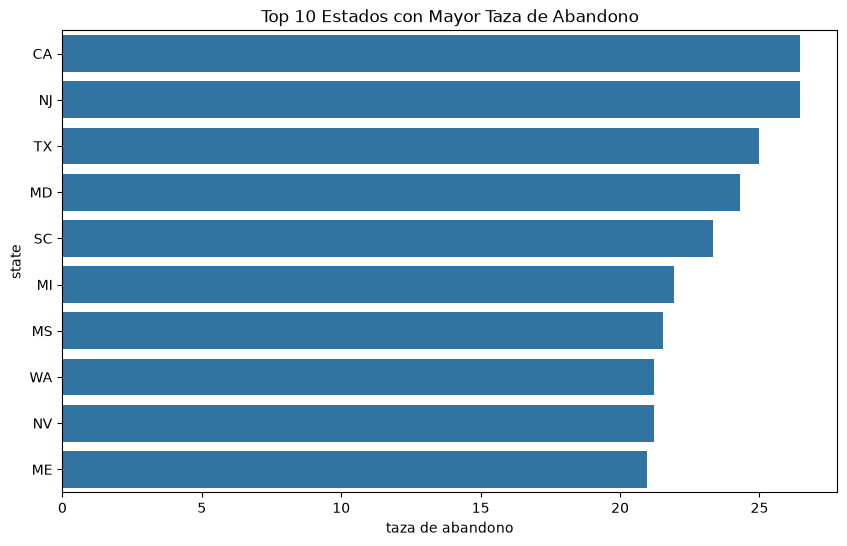

In [15]:
top_10_state = churn_state.head(10).sort_values(by='taza de abandono', ascending=False)
plt.figure(figsize=(10,6))
sns.barplot(data=top_10_state.reset_index(), x='taza de abandono', y='state')
plt.title('Top 10 Estados con Mayor Taza de Abandono')
plt.show()

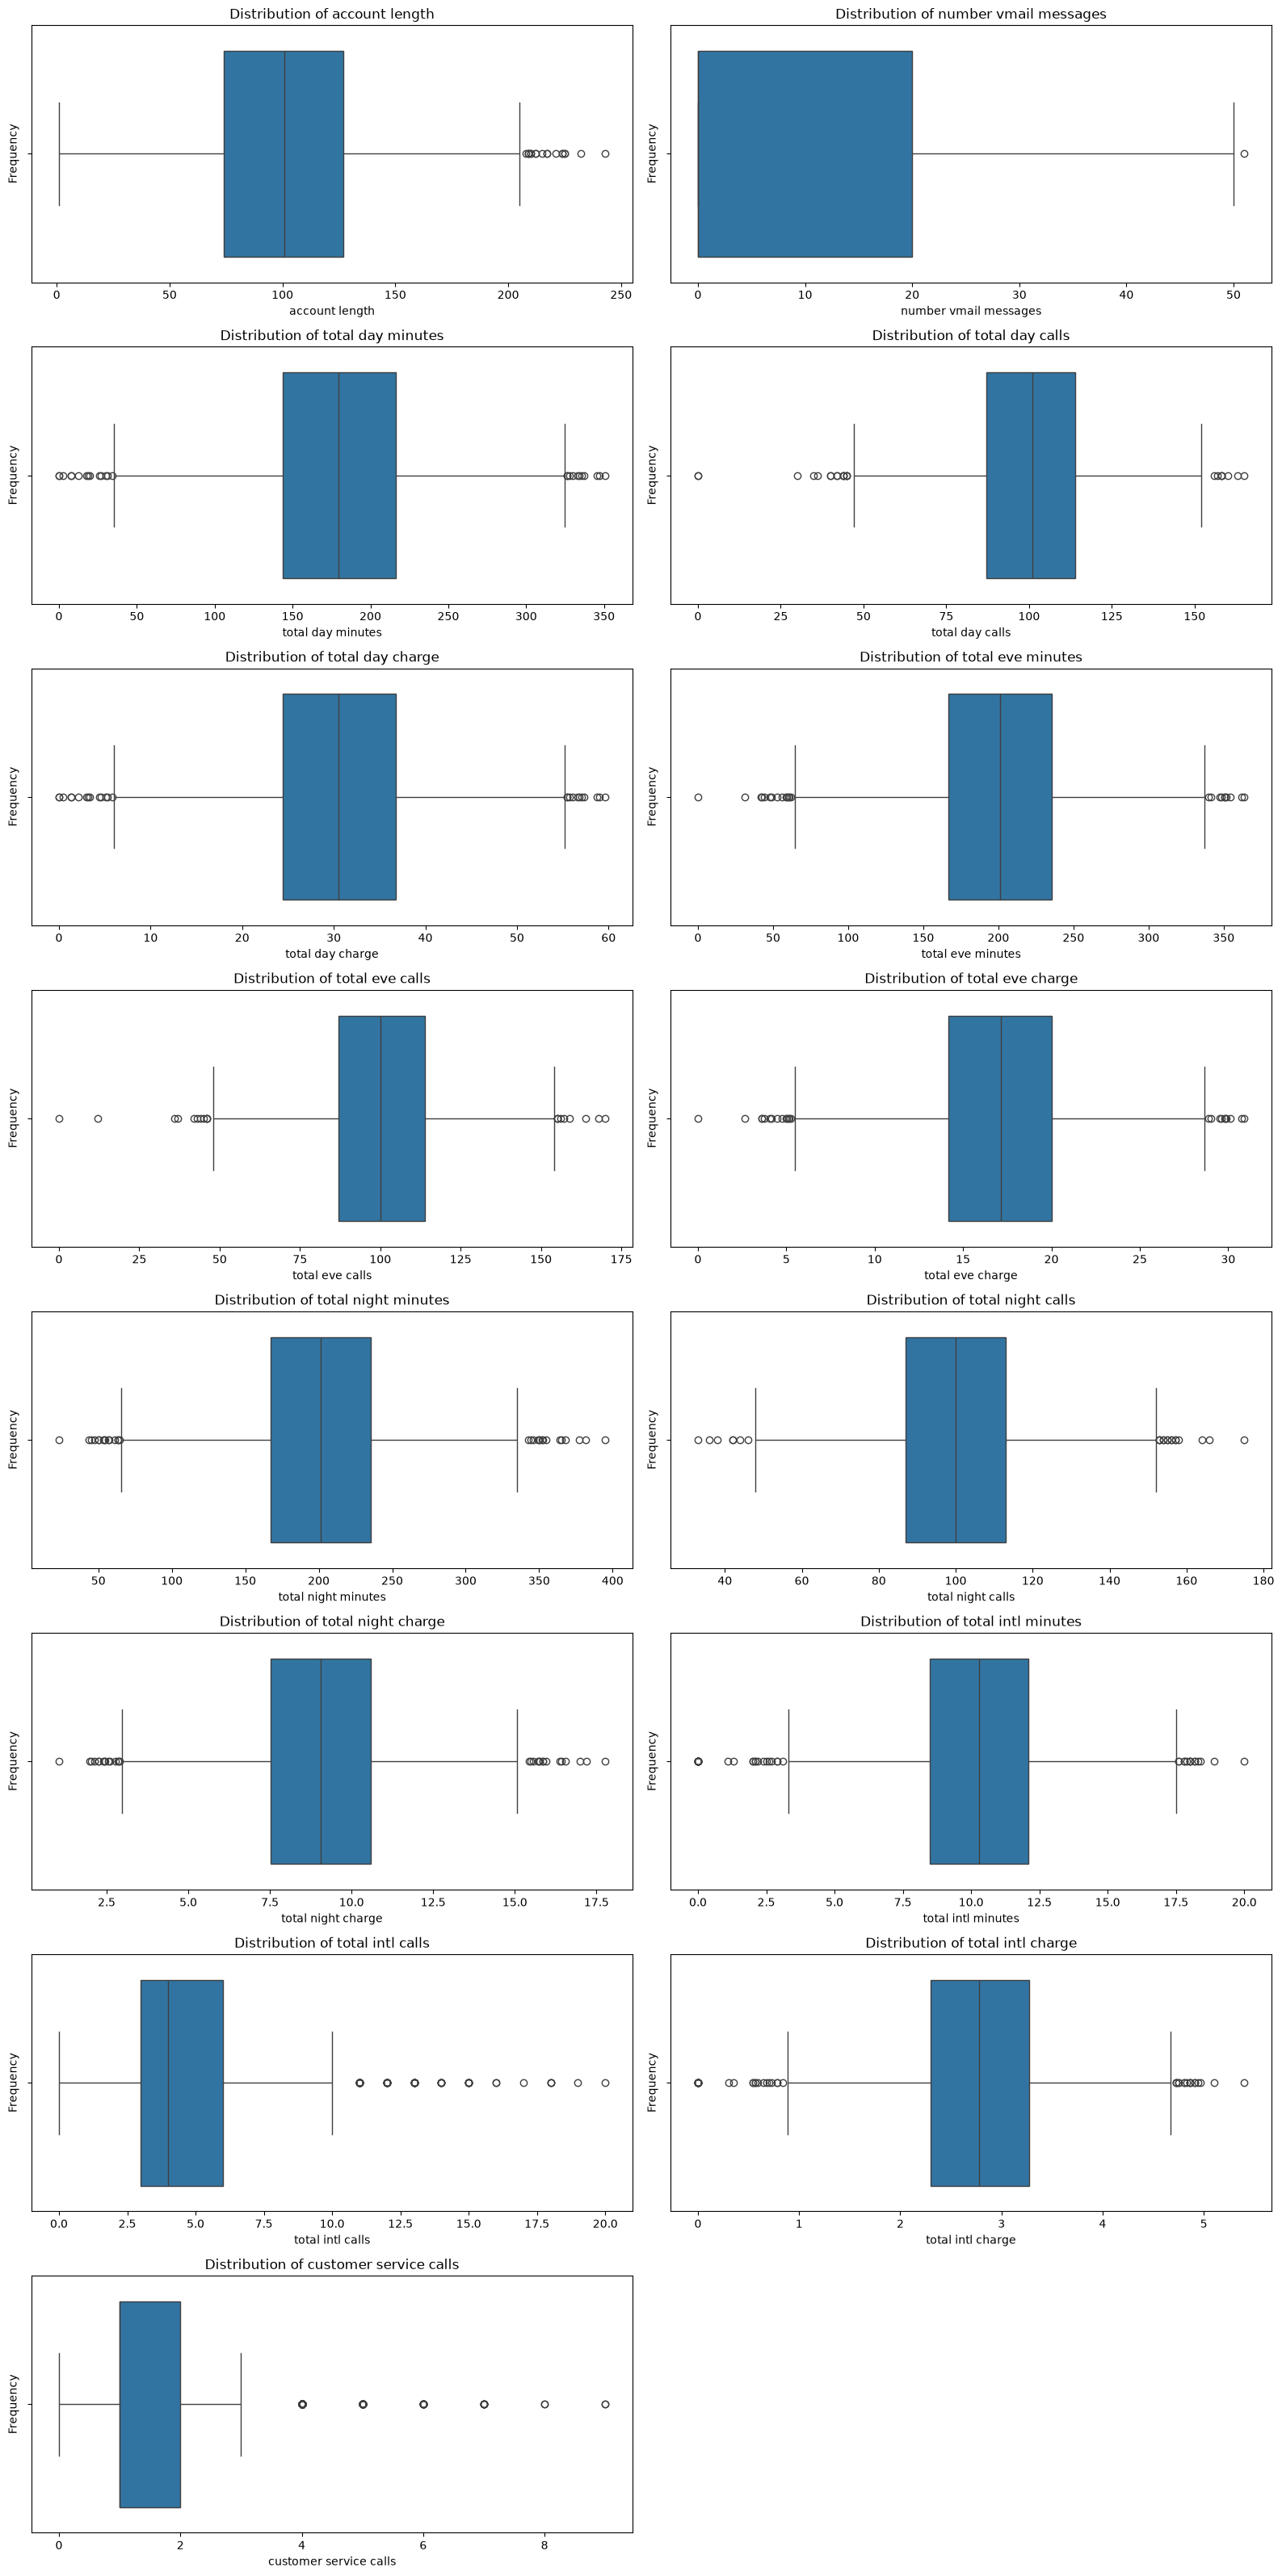

In [16]:
variables = [
    'account length',
    'number vmail messages',
    'total day minutes',
    'total day calls',
    'total day charge',
    'total eve minutes',
    'total eve calls',
    'total eve charge',
    'total night minutes',
    'total night calls',
    'total night charge',
    'total intl minutes',
    'total intl calls',
    'total intl charge',
    'customer service calls'
]
import math
n_cols = 2
n_rows = math.ceil(len(variables) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 4))
axes = axes.flatten()
for i, var in enumerate(variables):
    sns.boxplot(data=df, x=var, ax=axes[i])
    axes[i].set_title(f'Distribution of {var}')
    axes[i].set_xlabel(var)
    axes[i].set_ylabel('Frequency')

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()


In [17]:
resultados = []
for var in variables:
    Q1 = df[var].quantile(0.25)
    Q3 = df[var].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[var] < lower_bound) | (df[var] > upper_bound)]
    resultados.append({'variable': var,
                       'Q1' : Q1,
                       'Q3' : Q3,
                       'IQR' : IQR,
                       'lower_bound' : lower_bound,
                       'upper_bound' : upper_bound,
                       'outliers' : len(outliers),
                       'porcentaje': len(outliers) / len(df) * 100})
df_outliers = pd.DataFrame(resultados)
df_outliers.round(2)

,variable,Q1,Q3,IQR,lower_bound,upper_bound,outliers,porcentaje
0,account length,74.00,127.00,53.00,-5.50,206.50,18,0.54
1,number vmail messages,0.00,20.00,20.00,-30.00,50.00,1,0.03
2,total day minutes,143.70,216.40,72.70,34.65,325.45,25,0.75
3,total day calls,87.00,114.00,27.00,46.50,154.50,23,0.69
4,total day charge,24.43,36.79,12.36,5.89,55.33,25,0.75
5,total eve minutes,166.60,235.30,68.70,63.55,338.35,24,0.72
6,total eve calls,87.00,114.00,27.00,46.50,154.50,20,0.60
7,total eve charge,14.16,20.00,5.84,5.40,28.76,24,0.72
8,total night minutes,167.00,235.30,68.30,64.55,337.75,30,0.90
9,total night calls,87.00,113.00,26.00,48.00,152.00,22,0.66


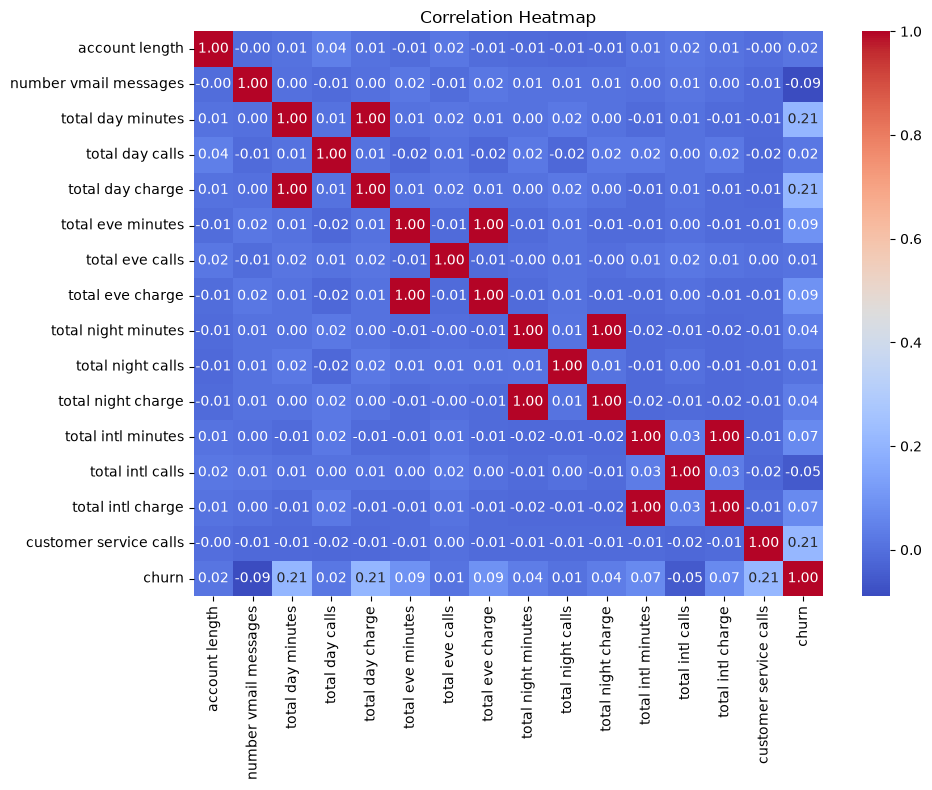

In [18]:
df_corr =df.copy()
df_corr['churn']= df_corr['churn'].astype(int)
df_numeric = df_corr.select_dtypes(include=['int64', 'float64', 'number'])
df_numeric = df_numeric.drop(columns=['area code'])
corr = df_numeric.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

In [19]:
correlacion_churn = corr['churn'].drop('churn').sort_values(ascending=False)
print(correlacion_churn.round(2))

customer service calls    0.21
total day minutes         0.21
total day charge          0.21
total eve minutes         0.09
total eve charge          0.09
total intl charge         0.07
total intl minutes        0.07
total night charge        0.04
total night minutes       0.04
total day calls           0.02
account length            0.02
total eve calls           0.01
total night calls         0.01
total intl calls         -0.05
number vmail messages    -0.09
Name: churn, dtype: float64


In [20]:
df_ml = df.drop(columns=['area code',
                         'phone number',
                         'total day charge',
                         'total eve charge',
                         'total night charge',
                         'total intl charge'])
X = df_ml.drop(columns=['churn'])
y = df_ml['churn']

In [21]:
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)
print("Variables Predictoras:", X.columns.tolist())
print("Distribucion de y:")
print(y.value_counts())

Dimensiones de X: (3333, 14)
Dimensiones de y: (3333,)
Variables Predictoras: ['state', 'account length', 'international plan', 'voice mail plan', 'number vmail messages', 'total day minutes', 'total day calls', 'total eve minutes', 'total eve calls', 'total night minutes', 'total night calls', 'total intl minutes', 'total intl calls', 'customer service calls']
Distribucion de y:
churn
False    2850
True      483
Name: count, dtype: int64


In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Dimensiones de X_train:", X_train.shape)
print("Dimensiones de X_test:", X_test.shape)
print("Dimensiones de y_train:", y_train.shape)
print("Dimensiones de y_test:", y_test.shape)
print("Distribucion de y_train:")
print(y_train.value_counts())
print("Distribucion de y_test:")
print(y_test.value_counts())

Dimensiones de X_train: (2666, 14)
Dimensiones de X_test: (667, 14)
Dimensiones de y_train: (2666,)
Dimensiones de y_test: (667,)
Distribucion de y_train:
churn
False    2284
True      382
Name: count, dtype: int64
Distribucion de y_test:
churn
False    566
True     101
Name: count, dtype: int64


In [23]:
print(f"Distribucion de entrenamiento: {y_train.value_counts(normalize=True) * 100}")
print(f"Distribucion de prueba: {y_test.value_counts(normalize=True) * 100}")

Distribucion de entrenamiento: churn
False    85.671418
True     14.328582
Name: proportion, dtype: float64
Distribucion de prueba: churn
False    84.857571
True     15.142429
Name: proportion, dtype: float64


In [24]:
categorical_features = ['state', 'international plan', 'voice mail plan']
numerical_features = X_test.select_dtypes(include=['number']).columns.tolist()

In [25]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

In [26]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
print("Original shape of training data:", X_train.shape)
print("Original shape of test data:", X_test.shape  )
print("Preprocessing completed.")
print("Shape of processed training data:", X_train_processed.shape)
print("Shape of processed test data:", X_test_processed.shape)


Original shape of training data: (2666, 14)
Original shape of test data: (667, 14)
Preprocessing completed.
Shape of processed training data: (2666, 66)
Shape of processed test data: (667, 66)


In [27]:

from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
tree_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

In [28]:
tree_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['state','account length','international plan',...,'total intl minutes', 'total intl calls','customer service calls']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of `

In [29]:
y_pred = tree_model.predict(X_test)
print(y_pred[:20])
print("predicciones :" , y_pred.shape)
print("valores reales :" , y_test.shape)

[False False  True False False False False False False False False False
 False  True False False False  True False False]
predicciones : (667,)
valores reales : (667,)


In [30]:
y_proba_pred = tree_model.predict_proba(X_test)
print(y_proba_pred[:20])
print("predicciones de probabilidad :" , y_proba_pred.shape)

[[1. 0.]
 [1. 0.]
 [0. 1.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [0. 1.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [0. 1.]
 [1. 0.]
 [1. 0.]]
predicciones de probabilidad : (667, 2)


In [31]:
resultados_tree = pd.DataFrame({
    'Real': y_test.astype(int).values,
    'Predicho': y_pred.astype(int),
    'Probabilidad': y_proba_pred[:, 1]
})

print(resultados_tree.head(20))

    Real  Predicho  Probabilidad
0      0         0           0.0
1      0         0           0.0
2      1         1           1.0
3      0         0           0.0
4      0         0           0.0
5      0         0           0.0
6      0         0           0.0
7      0         0           0.0
8      0         0           0.0
9      0         0           0.0
10     0         0           0.0
11     0         0           0.0
12     0         0           0.0
13     1         1           1.0
14     0         0           0.0
15     0         0           0.0
16     0         0           0.0
17     1         1           1.0
18     0         0           0.0
19     0         0           0.0


In [32]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score

print("Accuracy:", accuracy_score(y_test, y_pred))
print("confusion_matrix:\n", confusion_matrix(y_test, y_pred))
print("roc_auc_score:", roc_auc_score(y_test, y_proba_pred[:, 1]))
print("classification_report:\n", classification_report(y_test, y_pred))


Accuracy: 0.9310344827586207
confusion_matrix:
 [[546  20]
 [ 26  75]]
roc_auc_score: 0.8536192841899031
classification_report:
               precision    recall  f1-score   support

       False       0.95      0.96      0.96       566
        True       0.79      0.74      0.77       101

    accuracy                           0.93       667
   macro avg       0.87      0.85      0.86       667
weighted avg       0.93      0.93      0.93       667



In [33]:
y_train_pred = tree_model.predict(X_train)
y_test_pred = tree_model.predict(X_test)
accuracy_train = accuracy_score(y_train, y_train_pred)
accuracy_test = accuracy_score(y_test, y_test_pred)
print("Training Accuracy:", accuracy_train)
print("Testing Accuracy:", accuracy_test)
print("Difference:", accuracy_train - accuracy_test)


Training Accuracy: 1.0
Testing Accuracy: 0.9310344827586207
Difference: 0.06896551724137934


In [34]:
tree_classifier = tree_model.named_steps['classifier']
print("Profundidad del árbol:", tree_classifier.get_depth())
print("Número de nodos del árbol:", tree_classifier.tree_.node_count)
print("Número de hojas del árbol:", tree_classifier.get_n_leaves())

Profundidad del árbol: 21
Número de nodos del árbol: 343
Número de hojas del árbol: 172


In [35]:
DecisionTreeClassifier(
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [36]:
profundidades = [3, 5, 10, 15]
resultados_deph = []
for profundidad in profundidades:
    modelo = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('clasificacion', DecisionTreeClassifier(
            max_depth=profundidad,
            random_state=42
        ))
    ])
    modelo.fit(X_train, y_train)
    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)
    acc_train = accuracy_score(y_train, pred_train)
    acc_test = accuracy_score(y_test, pred_test)
    resultados_deph.append({
        'Max Depth': profundidad,
        'Accuracy Train': acc_train,
        'Accuracy Test': acc_test,
        'Diferencia': acc_train - acc_test
    })

df_deph = pd.DataFrame(resultados_deph)
df_deph.head()

,Max Depth,Accuracy Train,Accuracy Test,Diferencia
0,3,0.909977,0.893553,0.016424
1,5,0.957614,0.935532,0.022082
2,10,0.983871,0.935532,0.048339
3,15,0.993998,0.935532,0.058466


In [38]:
valores_split = [2, 5, 10, 20, 30, 50]
resultados_split = []
for valor in valores_split:
    modelo = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', DecisionTreeClassifier(
            max_depth= 5,
            min_samples_split=valor,
            random_state=42))
    ])
    modelo.fit(X_train, y_train)
    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    acc_train = accuracy_score(y_train, pred_train)
    acc_test = accuracy_score(y_test, pred_test)
    resultados_split.append({
        'Min Samples Split' : valor,
        'Acc Train' : acc_train,
        'Acc Test' : acc_test,
        'Diferencia' : acc_train - acc_test
    })
df_split = pd.DataFrame(resultados_split)
df_split.round(3)

,Min Samples Split,Acc Train,Acc Test,Diferencia
0,2,0.958,0.936,0.022
1,5,0.957,0.936,0.021
2,10,0.956,0.936,0.021
3,20,0.955,0.936,0.020
4,30,0.955,0.936,0.020
5,50,0.946,0.931,0.015


In [39]:
valores_leaf = [1, 2, 5, 10, 15, 20]
resultados_leaf = []
for valor in valores_leaf:
    modelo = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', DecisionTreeClassifier(
            max_depth= 5,
            min_samples_split=20,
            min_samples_leaf=valor,
            random_state=42))
    ])
    modelo.fit(X_train, y_train)
    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    acc_train = accuracy_score(y_train, pred_train)
    acc_test = accuracy_score(y_test, pred_test)
    resultados_leaf.append({
        'Min Samples Leaf' : valor,
        'Acc Train' : acc_train,
        'Acc Test' : acc_test,
        'Diferencia' : acc_train - acc_test
    })
df_leaf = pd.DataFrame(resultados_leaf)
df_leaf.round(3)

,Min Samples Leaf,Acc Train,Acc Test,Diferencia
0,1,0.955,0.936,0.020
1,2,0.955,0.937,0.018
2,5,0.954,0.937,0.017
3,10,0.953,0.939,0.014
4,15,0.950,0.940,0.010
5,20,0.946,0.931,0.015


In [40]:
tree_optimized = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        max_depth= 5,
        min_samples_split=20,
        min_samples_leaf=15,
        random_state=42))
])
tree_optimized.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['state','account length','international plan',...,'total intl minutes', 'total intl calls','customer service calls']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of `